In [ ]:
#1 — Import Libraries
import os
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.utils import load_img, img_to_array
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.20.0
GPU available: []


In [ ]:
#2 — Mount Google Drive
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
#3 — Set Dataset Path
DATASET_DIR = "/content/drive/MyDrive/RoadSense/dataset"
print("Dataset exists:", os.path.exists(DATASET_DIR))
print("Classes/Folders:", os.listdir(DATASET_DIR))

Dataset exists: True
Classes/Folders: ['pothole', 'cracks', 'normal']


In [ ]:
#4 — Basic Dataset Information
for class_name in sorted(os.listdir(DATASET_DIR)):
    class_path = os.path.join(DATASET_DIR, class_name)
    if os.path.isdir(class_path):
        count = len([
            f for f in os.listdir(class_path)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])
        print(f"{class_name}: {count} images")

cracks: 193 images
normal: 207 images
pothole: 284 images


In [ ]:
#5 — Parameters
IMG_SIZE = (128, 128)
BATCH_SIZE = 32
SEED = 42

In [ ]:
#6 — Load Training Data
train_data = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 684 files belonging to 3 classes.
Using 548 files for training.


In [ ]:
#7 — Load Validation Data
val_data = tf.keras.utils.image_dataset_from_directory(
    DATASET_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE
)

Found 684 files belonging to 3 classes.
Using 136 files for validation.


In [ ]:
#8 — Get Class Names
class_names = train_data.class_names

print("Classes found:", class_names)

Classes found: ['cracks', 'normal', 'pothole']


In [ ]:
#9 — Optimize Dataset Pipeline
AUTOTUNE = tf.data.AUTOTUNE

train_data = train_data.shuffle(1000).prefetch(
    buffer_size=AUTOTUNE
)

val_data = val_data.prefetch(
    buffer_size=AUTOTUNE
)

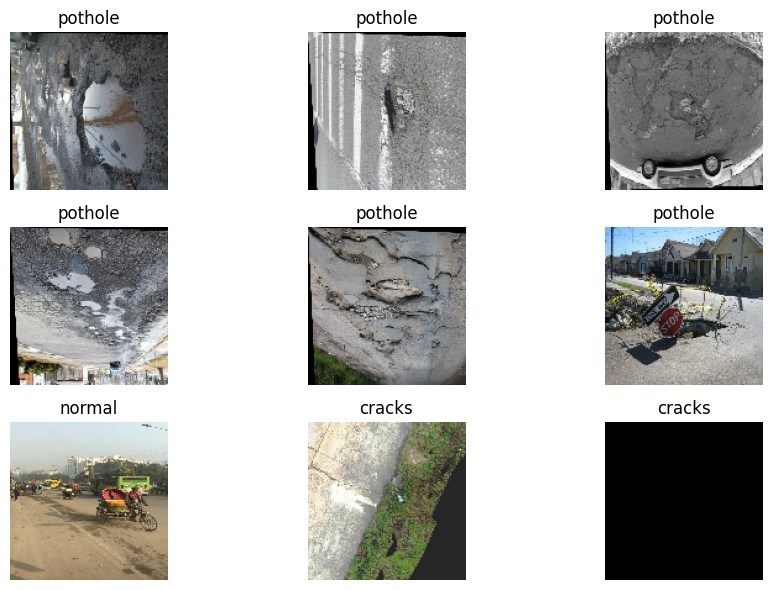

In [ ]:
#10 — Visualize Training Images
plt.figure(figsize=(10, 6))
for images, labels in train_data.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(
            images[i].numpy().astype("uint8")
        )
        plt.title(class_names[labels[i]])
        plt.axis("off")
plt.tight_layout()
plt.show()

In [ ]:
#11 — Data Augmentation
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
], name="data_augmentation")

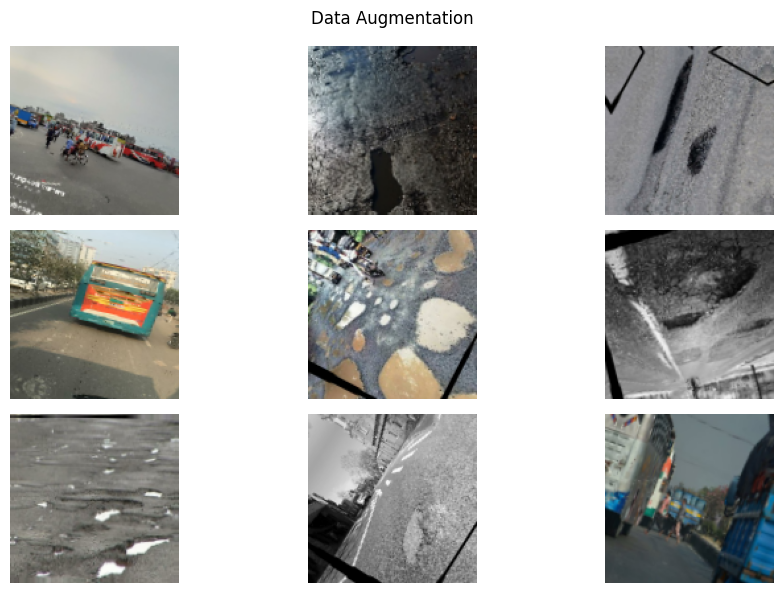

In [ ]:
#12 — Visualize Augmentation
for images, _ in train_data.take(1):

    plt.figure(figsize=(10, 6))

    for i in range(9):

        image = images[i:i+1]

        augmented = data_augmentation(
            image,
            training=True
        )

        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(
            augmented[0].numpy().astype("uint8")
        )

        plt.axis("off")

    plt.suptitle("Data Augmentation")
    plt.tight_layout()
    plt.show()

In [ ]:
#13 — Build CNN Model
model = tf.keras.Sequential([
    tf.keras.layers.Input(
        shape=(128, 128, 3)
    ),
    data_augmentation,
    tf.keras.layers.Rescaling(
        1./255
    ),
    tf.keras.layers.Conv2D(
        32,
        (3, 3),
        strides=1,
        padding="same",
        activation="relu",
        kernel_initializer="he_normal"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(
        (2, 2)
    ),
    tf.keras.layers.Conv2D(
        64,
        (3, 3),
        strides=1,
        padding="same",
        activation="relu",
        kernel_initializer="he_normal"
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D(
        (2, 2)
    ),
    tf.keras.layers.Conv2D(
        128,
        (3, 3),
        strides=1,
        padding="same",
        activation="relu",
        kernel_initializer="he_normal"
    ),
    tf.keras.layers.MaxPooling2D(
        (2, 2)
    ),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(
        128,
        activation="relu",
        kernel_initializer="he_normal"
    ),
    tf.keras.layers.Dropout(
        0.5
    ),
    tf.keras.layers.Dense(
        len(class_names),
        activation="softmax"
    )
], name="RoadSense_CNN")

model.summary()

Model: "RoadSense_CNN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │     4,194,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,288,451 (16.36 MB)

 Trainable params: 4,288,259 (16.36 MB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
#14 — Compile
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
#15 — Callbacks
early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "/content/roadsense_best_model.keras",
    monitor="val_accuracy",
    save_best_only=True
)

In [ ]:
#16 — Train the CNN
EPOCHS = 15
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=EPOCHS,
    callbacks=[
        early_stop,
        checkpoint
    ]
)

Epoch 1/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 72s 4s/step - accuracy: 0.6040 - loss: 9.3125 - val_accuracy: 0.3015 - val_loss: 3.4289
Epoch 2/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 40s 2s/step - accuracy: 0.7536 - loss: 1.7103 - val_accuracy: 0.3015 - val_loss: 3.7592
Epoch 3/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 41s 2s/step - accuracy: 0.7828 - loss: 0.5609 - val_accuracy: 0.5368 - val_loss: 1.0288
Epoch 4/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.8029 - loss: 0.4270 - val_accuracy: 0.7132 - val_loss: 0.6587
Epoch 5/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.8321 - loss: 0.4114 - val_accuracy: 0.5441 - val_loss: 0.8854
Epoch 6/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 39s 2s/step - accuracy: 0.8686 - loss: 0.3470 - val_accuracy: 0.7721 - val_loss: 0.7081
Epoch 7/15
18/18 ━━━━━━━━━━━━━━━━━━━━ 40s 2s/step - accuracy: 0.8376 - loss: 0.3861 - val_accuracy: 0.8235 - val_loss: 0.6724


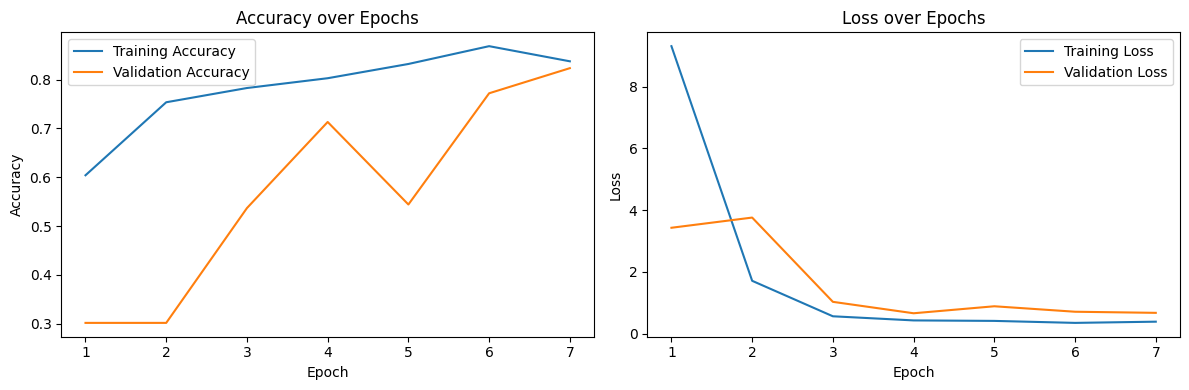

In [ ]:
#17 — Training Curves
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs_range = range(1, len(acc) + 1)
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(
    epochs_range,
    acc,
    label="Training Accuracy"
)
plt.plot(
    epochs_range,
    val_acc,
    label="Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy over Epochs")
plt.legend()

plt.subplot(1, 2, 2)

plt.plot(
    epochs_range,
    loss,
    label="Training Loss"
)

plt.plot(
    epochs_range,
    val_loss,
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss over Epochs")
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
#18 — Final Validation Evaluation
val_loss_final, val_acc_final = model.evaluate(
    val_data
)
print(
    f"Validation Loss: {val_loss_final:.4f}"
)
print(
    f"Validation Accuracy: {val_acc_final:.4f}"
)

5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 307ms/step - accuracy: 0.7132 - loss: 0.6587
Validation Loss: 0.6587
Validation Accuracy: 0.7132


In [ ]:
#19 — Collect Predictions
y_true = []
y_pred = []
for images, labels in val_data:
    predictions = model.predict(
        images,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    y_pred.extend(
        predicted_classes
    )

    y_true.extend(
        labels.numpy()
    )

y_true = np.array(y_true)
y_pred = np.array(y_pred)

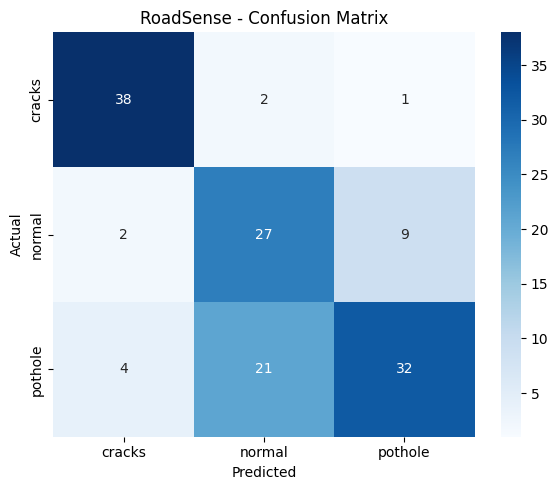

In [ ]:
#20 — Confusion Matrix
cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("RoadSense - Confusion Matrix")

plt.tight_layout()
plt.show()

In [ ]:
#21 — Classification Report
print(
    classification_report(
        y_true,
        y_pred,
        target_names=class_names
    )
)

              precision    recall  f1-score   support

      cracks       0.86      0.93      0.89        41
      normal       0.54      0.71      0.61        38
     pothole       0.76      0.56      0.65        57

    accuracy                           0.71       136
   macro avg       0.72      0.73      0.72       136
weighted avg       0.73      0.71      0.71       136



In [ ]:
# Overall Metrics
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
# Accuracy
accuracy = accuracy_score(y_true, y_pred)
# Precision
precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)
# Recall
recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)
# F1 Score
f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)
print("========== RoadSense Model Performance ==========")
print(f"Validation Loss     : {val_loss_final:.4f}")
print(f"Accuracy            : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Precision           : {precision:.4f}")
print(f"Recall              : {recall:.4f}")
print(f"F1 Score            : {f1:.4f}")
print("==================================================")

========== RoadSense Model Performance ==========
Validation Loss     : 0.6587
Accuracy            : 0.7132 (71.32%)
Precision           : 0.7306
Recall              : 0.7132
F1 Score            : 0.7120


In [ ]:
#22 — Test a New Image
def predict_road_image(
    image_path,
    model,
    class_names,
    img_size=(128, 128)
):
    img = load_img(
        image_path,
        target_size=img_size
    )
    img_array = img_to_array(img)
    img_array = np.expand_dims(
        img_array,
        axis=0
    )
    prediction = model.predict(
        img_array,
        verbose=0
    )
    index = np.argmax(
        prediction[0]
    )
    confidence = prediction[0][index]
    print(
        f"Prediction : {class_names[index]}"
    )
    print(
        f"Confidence : {confidence * 100:.2f}%"
    )
    plt.figure(figsize=(5, 5))
    plt.imshow(img)
    plt.axis("off")
    plt.title(
        f"{class_names[index]} "
        f"({confidence * 100:.1f}%)"
    )
    plt.show()
    return class_names[index], confidence

In [ ]:
#23 — Upload a New Road Image
from google.colab import files
uploaded = files.upload()

Saving Pretoria business people fix 500 POTHOLES.jpg to Pretoria business people fix 500 POTHOLES.jpg


Prediction : pothole
Confidence : 41.88%


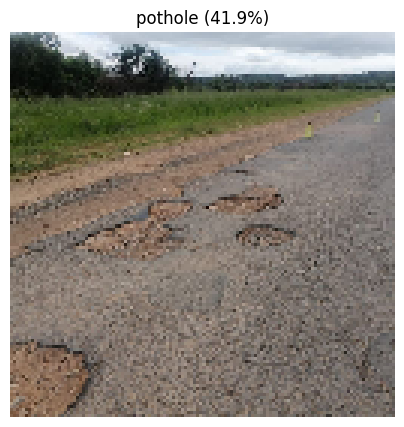

('pothole', np.float32(0.4187605))

In [ ]:
predict_road_image("Pretoria business people fix 500 POTHOLES.jpg",model,class_names)

In [ ]:
#24 — Save Final Model
model.save(
    "/content/roadsense_final_model.keras"
)

print(
    "Model saved successfully."
)

Model saved successfully.


In [ ]:
#25 — Save Model to Google Drive
import shutil
shutil.copy(
    "/content/roadsense_final_model.keras",
    "/content/drive/MyDrive/RoadSense/roadsense_final_model.keras"
)
print("Model saved to Google Drive.")

Model saved to Google Drive.


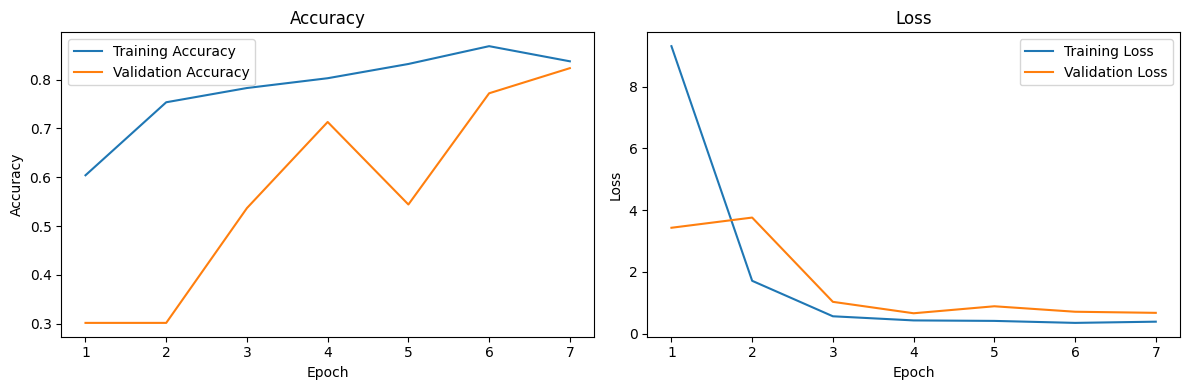

In [ ]:
#Save Training Graph
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(
    epochs_range,
    acc,
    label="Training Accuracy"
)
plt.plot(
    epochs_range,
    val_acc,
    label="Validation Accuracy"
)
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Accuracy")
plt.legend()
plt.subplot(1, 2, 2)
plt.plot(
    epochs_range,
    loss,
    label="Training Loss"
)
plt.plot(
    epochs_range,
    val_loss,
    label="Validation Loss"
)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Loss")
plt.legend()
plt.tight_layout()
plt.savefig(
    "/content/drive/MyDrive/RoadSense/training_curves.png",
    dpi=150
)
plt.show()

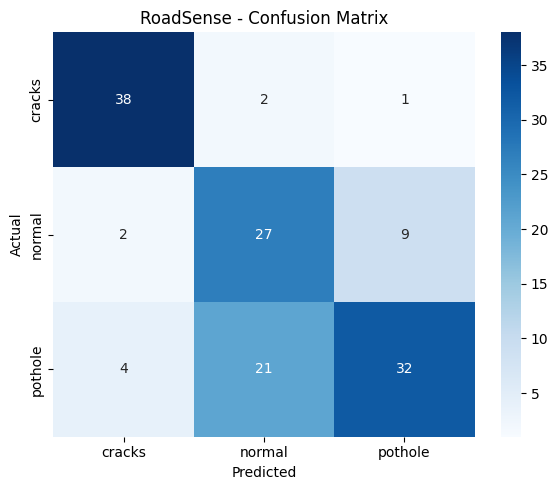

In [ ]:
#Save Confusion Matrix
plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("RoadSense - Confusion Matrix")
plt.tight_layout()
plt.savefig(
    "/content/drive/MyDrive/RoadSense/confusion_matrix.png",
    dpi=150
)
plt.show()